# 2 — Feature-generator behavior and predictive analysis

Reproduces the core study analysis: baseline and augmented regressions, repeated-inference stability, model-pair disagreement, severity mapping, practical-performance tolerance sensitivity, and persistent disagreements. All resampling is over unique descriptions.

**Paper coverage:** §§4.1–4.3, Table 3, Figure 2, and the full-description diagnostics indexed in SUPPLEMENT.md. Notebook 5 produces the validation-weighted Figure 1 and the current fixed-batch intervals.

Use the pinned environment in [README.md](README.md#run-the-analysis). Run cells from top to bottom; saved inference caches allow reproduction without API keys or new requests.


In [1]:
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.metrics import cohen_kappa_score
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "s0_get_data.ipynb").exists()), Path.cwd())
TABLES, FIGURES = ROOT / "tables", ROOT / "figures"
PAPER_FIGURES = ROOT / "paper_naaj" / "figures"
TABLES.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
if (ROOT / "paper_naaj").exists():
    PAPER_FIGURES.mkdir(parents=True, exist_ok=True)

claims = pd.read_csv(ROOT / "data" / "processed" / "claims.csv")
descriptions = pd.read_csv(ROOT / "data" / "processed" / "descriptions.csv")
labels = pd.read_csv(ROOT / "data" / "results" / "classifications.csv")
fixed_labels = pd.read_csv(ROOT / "data" / "results" / "classifications_fixed.csv")
fixed_manifest = pd.read_csv(ROOT / "data" / "results" / "fixed_batch_manifest.csv")
baseline = pd.read_csv(TABLES / "baseline_performance.csv")
roster = pd.read_csv(TABLES / "model_roster.csv")
PERILS = ["Vandalism", "Fire", "Lightning", "Wind", "Hail", "Vehicle", "WaterNW", "WaterW", "Misc"]
MODEL_ORDER = roster["model"].tolist()
LABEL_NAMES = ["negligible", "low", "medium", "high", "catastrophic"]
RUNS = sorted(labels["run"].unique())

expected = len(descriptions) * len(MODEL_ORDER) * len(RUNS)
assert len(labels) == expected, f"Incomplete classifications: expected {expected:,}, found {len(labels):,}"
assert not labels[["description_id", "model", "run"]].duplicated().any()
fixed_expected = len(fixed_manifest) * len(MODEL_ORDER) * len(RUNS)
assert len(fixed_labels) == fixed_expected
assert not fixed_labels[["description_id", "model", "run"]].duplicated().any()
print(
    f"Analyzing {len(labels):,} randomized-batch and {len(fixed_labels):,} "
    f"fixed-batch classifications."
)


Analyzing 140,700 randomized-batch and 30,000 fixed-batch classifications.


## Downstream predictive performance

For each model/run, the generated ordinal feature is inserted into the replicated Gamma GLM. R² and MAE are calculated on `log1p(Loss)`, matching the published analysis.

**Reports:** §4.1; Table 3 and MAE-improvement intervals in SUPPLEMENT.md.


In [2]:
def regression_metrics(y, pred, p):
    y, pred = np.asarray(y), np.asarray(pred)
    r2 = 1 - np.square(y - pred).sum() / np.square(y - y.mean()).sum()
    return {
        "r2": r2,
        "adjusted_r2": 1 - (1 - r2) * (len(y) - 1) / (len(y) - p - 1),
        "mae": np.abs(y - pred).mean(),
    }

# Retain paired validation errors for a small uncertainty check on the replicated regression.
baseline_train = claims.query("split == 'train'")
baseline_valid = claims.query("split == 'validation'")
baseline_feature_cols = PERILS[:-1]
baseline_x_train = sm.add_constant(baseline_train[baseline_feature_cols], has_constant="add")
baseline_x_valid = sm.add_constant(baseline_valid[baseline_feature_cols], has_constant="add")
baseline_fit = sm.GLM(
    baseline_train["log_loss"], baseline_x_train,
    family=sm.families.Gamma(link=sm.families.links.Log()),
).fit()
baseline_validation_errors = np.abs(
    baseline_valid["log_loss"].to_numpy() - baseline_fit.predict(baseline_x_valid).to_numpy()
)
model_validation_errors = {model: [] for model in MODEL_ORDER}

performance_rows = []
for model in MODEL_ORDER:
    for run in RUNS:
        feature = labels.query("model == @model and run == @run")[["description_id", "label_value"]]
        data = claims.merge(feature, on="description_id", how="left", validate="many_to_one")
        train = data.query("split == 'train'")
        valid = data.query("split == 'validation'")
        feature_cols = PERILS[:-1] + ["label_value"]
        x_train = sm.add_constant(train[feature_cols], has_constant="add")
        x_valid = sm.add_constant(valid[feature_cols], has_constant="add")
        fit = sm.GLM(
            train["log_loss"], x_train,
            family=sm.families.Gamma(link=sm.families.links.Log()),
        ).fit()
        train_pred = fit.predict(x_train)
        valid_pred = fit.predict(x_valid)
        assert np.array_equal(valid["description_id"].to_numpy(), baseline_valid["description_id"].to_numpy())
        model_validation_errors[model].append(np.abs(valid["log_loss"].to_numpy() - valid_pred.to_numpy()))
        performance_rows.extend([
            {"model": model, "run": run, "split": "train", **regression_metrics(train.log_loss, train_pred, len(feature_cols))},
            {"model": model, "run": run, "split": "validation", **regression_metrics(valid.log_loss, valid_pred, len(feature_cols))},
        ])

performance = pd.DataFrame(performance_rows)
performance.to_csv(TABLES / "performance_by_run.csv", index=False)
validation_performance = performance.query("split == 'validation'")
performance_summary = (
    validation_performance.groupby("model", as_index=False)
    .agg(mean_mae=("mae", "mean"), sd_mae=("mae", "std"), mean_r2=("r2", "mean"), sd_r2=("r2", "std"))
)
performance_summary["model"] = pd.Categorical(performance_summary["model"], MODEL_ORDER, ordered=True)
performance_summary = performance_summary.sort_values("model")
display(performance_summary.round(4))


,model,mean_mae,sd_mae,mean_r2,sd_r2
2,GPT-5.6 Sol,0.9906,0.0133,0.4283,0.0125
3,Gemini 3.1 Pro,0.9794,0.0039,0.4356,0.0032
4,Kimi K2.6,1.0037,0.0091,0.4100,0.0078
0,DeepSeek V4 Pro,1.0050,0.0051,0.4137,0.0039
5,Qwen3.5 397B,1.0143,0.0026,0.4046,0.0020
1,GLM-5.2,1.0006,0.0095,0.4151,0.0099


### MAE improvement uncertainty

**Reports:** §4.1; 5,000 paired validation-description resamples, retaining repeated claims.


In [3]:
# Paired percentile bootstrap by unique description (5,000 replicates).
# Positive values mean that the LLM feature lowers validation MAE.
bootstrap_rng = np.random.default_rng(20260812)
bootstrap_rows = []
baseline_validation_mae = baseline_validation_errors.mean()
for model in MODEL_ORDER:
    model_error = np.vstack(model_validation_errors[model]).mean(axis=0)
    improvement = baseline_validation_errors - model_error
    clustered = (
        pd.DataFrame({"description_id": baseline_valid["description_id"].to_numpy(), "improvement": improvement})
        .groupby("description_id", as_index=False)
        .agg(improvement_sum=("improvement", "sum"), claim_count=("improvement", "size"))
    )
    boot = np.empty(5_000)
    for b in range(len(boot)):
        sampled = bootstrap_rng.integers(0, len(clustered), size=len(clustered))
        boot[b] = (
            clustered["improvement_sum"].to_numpy()[sampled].sum()
            / clustered["claim_count"].to_numpy()[sampled].sum()
        )
    ci_low, ci_high = np.quantile(boot, [0.025, 0.975])
    point = improvement.mean()
    bootstrap_rows.append({
        "model": model,
        "mean_mae_improvement": point,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "mean_improvement_pct_baseline": 100 * point / baseline_validation_mae,
        "ci_low_pct_baseline": 100 * ci_low / baseline_validation_mae,
        "ci_high_pct_baseline": 100 * ci_high / baseline_validation_mae,
        "bootstrap_unit": "description",
        "bootstrap_replicates": len(boot),
    })

mae_improvement_bootstrap = pd.DataFrame(bootstrap_rows)
mae_improvement_bootstrap.to_csv(TABLES / "mae_improvement_bootstrap.csv", index=False)
display(mae_improvement_bootstrap.round(4))


,model,mean_mae_improvement,ci_low,ci_high,mean_improvement_pct_baseline,ci_low_pct_baseline,ci_high_pct_baseline,bootstrap_unit,bootstrap_replicates
0,GPT-5.6 Sol,0.0788,0.0583,0.0987,7.3699,5.4493,9.2279,description,5000
1,Gemini 3.1 Pro,0.0900,0.0681,0.1130,8.4132,6.3642,10.5663,description,5000
2,Kimi K2.6,0.0657,0.0492,0.0832,6.1404,4.6005,7.7790,description,5000
3,DeepSeek V4 Pro,0.0644,0.0463,0.0823,6.0212,4.3279,7.6963,description,5000
4,Qwen3.5 397B,0.0551,0.0398,0.0703,5.1534,3.7220,6.5752,description,5000
5,GLM-5.2,0.0688,0.0509,0.0868,6.4361,4.7565,8.1207,description,5000


## Randomized-batch stability and between-model heterogeneity

The original five runs deliberately changed neighboring descriptions. Their within-model statistics therefore represent combined rerun and batch-context variability—not pure repeated-inference instability. Pairwise model comparisons below remain useful descriptively, but no ratio between modal-label and run-level quantities is treated as a headline result.

**Reports:** SUPPLEMENT.md: randomized-batch stability and full-description agreement.


In [4]:
def mean_pairwise_abs(values):
    values = np.asarray(values, dtype=float)
    return np.mean([abs(values[i] - values[j]) for i, j in combinations(range(len(values)), 2)])

within_claim = (
    labels.groupby(["model", "description_id"])["label_value"]
    .agg(list)
    .reset_index(name="values")
)
within_claim["all_same"] = within_claim["values"].map(lambda x: len(set(x)) == 1)
within_claim["any_variation"] = ~within_claim["all_same"]
within_claim["mean_pairwise_abs"] = within_claim["values"].map(mean_pairwise_abs)
within_claim["span_ge_2"] = within_claim["values"].map(lambda x: max(x) - min(x) >= 2)

within_rows = []
for model in MODEL_ORDER:
    sub = labels.query("model == @model")
    wide = sub.pivot(index="description_id", columns="run", values="label_value")
    exacts, kappas = [], []
    for r1, r2 in combinations(RUNS, 2):
        exacts.append((wide[r1] == wide[r2]).mean())
        kappas.append(cohen_kappa_score(wide[r1], wide[r2], weights="quadratic"))
    claim_sub = within_claim.query("model == @model")
    within_rows.append({
        "model": model,
        "all_five_same": claim_sub["all_same"].mean(),
        "average_pairwise_exact_agreement": np.mean(exacts),
        "average_pairwise_weighted_kappa": np.mean(kappas),
        "within_model_distance": claim_sub["mean_pairwise_abs"].mean(),
        "any_run_variation": claim_sub["any_variation"].mean(),
        "span_ge_2": claim_sub["span_ge_2"].mean(),
    })
within = pd.DataFrame(within_rows)

def modal_record(group):
    counts = group["label_value"].value_counts()
    candidates = counts[counts == counts.max()].index.to_numpy()
    median = group["label_value"].median()
    # Preserve the original saved-data rule explicitly: frequency, median distance, earliest run.
    modal_value = int(min(candidates, key=lambda value: (
        abs(value - median), int(group.loc[group["label_value"].eq(value), "run"].min())
    )))
    return pd.Series({
        "modal_value": modal_value,
        "modal_label": LABEL_NAMES[modal_value - 1],
        "modal_count": int(counts.max()),
        "consistency": counts.max() / len(group),
    })

modal = labels.groupby(["model", "description_id"], sort=False).apply(modal_record, include_groups=False).reset_index()
modal_wide = modal.pivot(index="description_id", columns="model", values="modal_value")[MODEL_ORDER]

pair_rows = []
between_vectors = {}
for model_a, model_b in combinations(MODEL_ORDER, 2):
    a, b = modal_wide[model_a].to_numpy(), modal_wide[model_b].to_numpy()
    distance = np.abs(a - b)
    key = f"{model_a} | {model_b}"
    between_vectors[key] = distance
    pair_rows.append({
        "model_a": model_a, "model_b": model_b,
        "exact_agreement": np.mean(a == b),
        "disagreement_rate": np.mean(a != b),
        "weighted_kappa": cohen_kappa_score(a, b, weights="quadratic"),
        "between_model_distance": distance.mean(),
        "differ_by_2_plus": np.mean(distance >= 2),
    })
between = pd.DataFrame(pair_rows)
average_between_modal = np.mean(np.concatenate(list(between_vectors.values())))
average_randomized_within = within_claim["mean_pairwise_abs"].mean()

model_summary = performance_summary.merge(within, on="model")
model_summary.to_csv(TABLES / "model_summary.csv", index=False)
between.to_csv(TABLES / "pairwise_behavior.csv", index=False)
modal.to_csv(ROOT / "data" / "results" / "modal_classifications.csv", index=False)
display(model_summary.round(4))
print(f"Randomized-batch within-model distance: {average_randomized_within:.4f}")
print(f"Between-model modal-label distance: {average_between_modal:.4f}")
print("Reported separately: the first is run-level; the second is denoised by modal aggregation.")


,model,mean_mae,sd_mae,mean_r2,sd_r2,all_five_same,average_pairwise_exact_agreement,average_pairwise_weighted_kappa,within_model_distance,any_run_variation,span_ge_2
0,GPT-5.6 Sol,0.9906,0.0133,0.4283,0.0125,0.4525,0.7320,0.7430,0.2696,0.5475,0.0096
1,Gemini 3.1 Pro,0.9794,0.0039,0.4356,0.0032,0.4738,0.7410,0.8358,0.2605,0.5262,0.0083
2,Kimi K2.6,1.0037,0.0091,0.4100,0.0078,0.4196,0.7160,0.7041,0.2886,0.5804,0.0247
3,DeepSeek V4 Pro,1.0050,0.0051,0.4137,0.0039,0.3495,0.6751,0.7081,0.3329,0.6505,0.0426
4,Qwen3.5 397B,1.0143,0.0026,0.4046,0.0020,0.3200,0.6555,0.6377,0.3536,0.6800,0.0480
5,GLM-5.2,1.0006,0.0095,0.4151,0.0099,0.3966,0.6958,0.6970,0.3098,0.6034,0.0320


Randomized-batch within-model distance: 0.3025
Between-model modal-label distance: 0.2833
Reported separately: the first is run-level; the second is denoised by modal aggregation.


## Bootstrap uncertainty

Percentile intervals use 1,000 bootstrap samples of unique descriptions. The primary estimands are each model's within-model ordinal distance and each pair's between-model ordinal distance/disagreement rate.

**Reports:** SUPPLEMENT.md: original description-bootstrap diagnostics. Current fixed-input batch intervals come from Notebook 5.


In [5]:
RNG = np.random.default_rng(20260812)
BOOTSTRAPS = 1000

def bootstrap_mean_ci(values):
    values = np.asarray(values, dtype=float)
    estimates = np.empty(BOOTSTRAPS)
    for b in range(BOOTSTRAPS):
        estimates[b] = values[RNG.integers(0, len(values), len(values))].mean()
    return np.quantile(estimates, [0.025, 0.975])

bootstrap_rows = []
for model in MODEL_ORDER:
    values = within_claim.query("model == @model")["mean_pairwise_abs"].to_numpy()
    lo, hi = bootstrap_mean_ci(values)
    bootstrap_rows.append({"scope": "within", "comparison": model, "metric": "ordinal_distance", "estimate": values.mean(), "ci_low": lo, "ci_high": hi})

for _, row in between.iterrows():
    key = f"{row.model_a} | {row.model_b}"
    distance = between_vectors[key]
    for metric, values in [("ordinal_distance", distance), ("disagreement_rate", distance > 0)]:
        lo, hi = bootstrap_mean_ci(values)
        bootstrap_rows.append({"scope": "between", "comparison": key, "metric": metric, "estimate": np.mean(values), "ci_low": lo, "ci_high": hi})

bootstrap = pd.DataFrame(bootstrap_rows)
bootstrap.to_csv(TABLES / "bootstrap_intervals.csv", index=False)
display(bootstrap.head().round(4))


,scope,comparison,metric,estimate,ci_low,ci_high
0,within,GPT-5.6 Sol,ordinal_distance,0.2696,0.2625,0.2768
1,within,Gemini 3.1 Pro,ordinal_distance,0.2605,0.2535,0.2682
2,within,Kimi K2.6,ordinal_distance,0.2886,0.2811,0.2961
3,within,DeepSeek V4 Pro,ordinal_distance,0.3329,0.3246,0.3404
4,within,Qwen3.5 397B,ordinal_distance,0.3536,0.3459,0.3613


## Three-source variation decomposition

The 1,000-description fixed-batch experiment holds the other 19 descriptions and their order constant across five new repetitions. Three like-for-like run-level quantities are calculated on that same sample:

1. **Fixed-batch rerun:** same model, same batch, two independent runs.
2. **Randomized-batch operation:** same model, but runs also change neighboring descriptions; this combines rerun and context effects.
3. **Model change under fixed batching:** two different models, with batch membership/order held constant, averaging all cross-model run pairs.

The second minus the first is shown as a descriptive incremental batch-context component, not assumed to be an additive causal estimate. Modal shifts between fixed and randomized experiments are also reported separately.

**Reports:** SUPPLEMENT.md: fixed versus randomized context; descriptive comparison, not a causal decomposition.


In [6]:
fixed_ids = set(fixed_manifest["description_id"])
randomized_sample = labels[labels["description_id"].isin(fixed_ids)].copy()
assert randomized_sample["description_id"].nunique() == len(fixed_manifest)

def claim_pairwise_distances(frame):
    return (
        frame.groupby(["model", "description_id"])["label_value"]
        .agg(list).reset_index(name="values")
        .assign(distance=lambda x: x["values"].map(mean_pairwise_abs))
    )

fixed_within_claim = claim_pairwise_distances(fixed_labels)
randomized_sample_within = claim_pairwise_distances(randomized_sample)

fixed_wide = fixed_labels.pivot(
    index="description_id", columns=["model", "run"], values="label_value"
)
between_fixed_claim = pd.DataFrame(index=fixed_wide.index)
for model_a, model_b in combinations(MODEL_ORDER, 2):
    distances = []
    for run_a in RUNS:
        for run_b in RUNS:
            distances.append(
                (fixed_wide[(model_a, run_a)] - fixed_wide[(model_b, run_b)]).abs()
            )
    between_fixed_claim[f"{model_a} | {model_b}"] = pd.concat(distances, axis=1).mean(axis=1)
between_fixed_vector = between_fixed_claim.mean(axis=1)

def modal_table(frame):
    return (
        frame.groupby(["model", "description_id"], sort=False)
        .apply(modal_record, include_groups=False).reset_index()
    )

fixed_modal = modal_table(fixed_labels)
randomized_sample_modal = modal[modal["description_id"].isin(fixed_ids)].copy()
fixed_modal_wide = fixed_modal.pivot(
    index="description_id", columns="model", values="modal_value"
)[MODEL_ORDER]
randomized_sample_modal_wide = randomized_sample_modal.pivot(
    index="description_id", columns="model", values="modal_value"
)[MODEL_ORDER]

decomposition_rows = []
for model in MODEL_ORDER:
    fixed_values = fixed_within_claim.query("model == @model").set_index("description_id")["distance"]
    randomized_values = randomized_sample_within.query("model == @model").set_index("description_id")["distance"]
    modal_shift = (
        fixed_modal_wide[model] - randomized_sample_modal_wide[model]
    ).abs()
    decomposition_rows.append({
        "model": model,
        "fixed_batch_rerun_distance": fixed_values.mean(),
        "randomized_batch_operational_distance": randomized_values.mean(),
        "increment_associated_with_randomized_batching": randomized_values.mean() - fixed_values.mean(),
        "fixed_vs_randomized_modal_shift": modal_shift.mean(),
        "fixed_vs_randomized_modal_disagreement": (modal_shift > 0).mean(),
        "fixed_vs_randomized_modal_two_plus": (modal_shift >= 2).mean(),
    })
variation_by_model = pd.DataFrame(decomposition_rows)
variation_by_model.to_csv(TABLES / "variation_decomposition_by_model.csv", index=False)

fixed_within_vector = fixed_within_claim.groupby("description_id")["distance"].mean()
randomized_within_vector = randomized_sample_within.groupby("description_id")["distance"].mean()
variation_vectors = {
    "Fixed-batch rerun": fixed_within_vector,
    "Randomized-batch operation": randomized_within_vector,
    "Model change, fixed batch": between_fixed_vector,
}
variation_summary_rows = []
for source, vector in variation_vectors.items():
    lo, hi = bootstrap_mean_ci(vector.to_numpy())
    variation_summary_rows.append({
        "source": source, "mean_ordinal_distance": vector.mean(),
        "ci_low": lo, "ci_high": hi,
    })
variation_summary = pd.DataFrame(variation_summary_rows)
fixed_rerun_reference = variation_summary.loc[
    variation_summary["source"] == "Fixed-batch rerun", "mean_ordinal_distance"
].iloc[0]
variation_summary["relative_to_fixed_rerun"] = (
    variation_summary["mean_ordinal_distance"] / fixed_rerun_reference
)
variation_summary.to_csv(TABLES / "variation_decomposition.csv", index=False)
display(variation_by_model.round(4))
display(variation_summary.round(4))


,model,fixed_batch_rerun_distance,randomized_batch_operational_distance,increment_associated_with_randomized_batching,fixed_vs_randomized_modal_shift,fixed_vs_randomized_modal_disagreement,fixed_vs_randomized_modal_two_plus
0,GPT-5.6 Sol,0.1342,0.2796,0.1454,0.183,0.183,0.000
1,Gemini 3.1 Pro,0.0818,0.2574,0.1756,0.169,0.169,0.000
2,Kimi K2.6,0.1182,0.2984,0.1802,0.202,0.201,0.001
3,DeepSeek V4 Pro,0.1134,0.3416,0.2282,0.222,0.219,0.003
4,Qwen3.5 397B,0.0566,0.3504,0.2938,0.206,0.204,0.002
5,GLM-5.2,0.1284,0.3218,0.1934,0.204,0.204,0.000


,source,mean_ordinal_distance,ci_low,ci_high,relative_to_fixed_rerun
0,Fixed-batch rerun,0.1054,0.1001,0.1117,1.0000
1,Randomized-batch operation,0.3082,0.2999,0.3172,2.9232
2,"Model change, fixed batch",0.3545,0.3421,0.3667,3.3623


## Severity mapping and implicit thresholds

Marginal category use is computed over unique descriptions, preventing repeated descriptions from receiving extra weight. Because every record is an already-realized incident and the target is loss magnitude, these are severity mappings—not actuarial frequency-risk estimates. Realized severity is summarized separately on training claims only, preserving out-of-sample validation for predictive evaluation.

**Reports:** §4.3; Figure 2.


In [7]:
severity_observed = (
    modal.groupby(["model", "modal_value", "modal_label"], as_index=False)
    .agg(descriptions=("description_id", "size"))
)
severity_grid = pd.MultiIndex.from_product(
    [MODEL_ORDER, range(1, 6)], names=["model", "modal_value"]
).to_frame(index=False)
severity_grid["modal_label"] = severity_grid["modal_value"].map(lambda value: LABEL_NAMES[value - 1])
category_use = severity_grid.merge(
    severity_observed, on=["model", "modal_value", "modal_label"], how="left"
)
category_use["descriptions"] = category_use["descriptions"].fillna(0).astype(int)
category_use["share"] = category_use["descriptions"] / category_use.groupby("model")["descriptions"].transform("sum")

train_claims = claims.query("split == 'train'")
loss_by_severity = (
    train_claims.merge(modal, on="description_id", how="left", validate="many_to_many")
    .groupby(["model", "modal_value", "modal_label"], as_index=False)
    .agg(claims=("Loss", "size"), mean_loss=("Loss", "mean"), median_loss=("Loss", "median"), mean_log_loss=("log_loss", "mean"))
)
severity_mapping = category_use.merge(loss_by_severity, on=["model", "modal_value", "modal_label"], how="left")
severity_mapping.to_csv(TABLES / "severity_mapping.csv", index=False)
display(severity_mapping.round(3))


,model,modal_value,modal_label,descriptions,share,claims,mean_loss,median_loss,mean_log_loss
0,GPT-5.6 Sol,1,negligible,78,0.017,72.0,548.845,388.115,5.702
1,GPT-5.6 Sol,2,low,1813,0.387,1958.0,2627.915,732.510,6.649
2,GPT-5.6 Sol,3,medium,2253,0.480,2518.0,21166.682,3850.065,8.372
3,GPT-5.6 Sol,4,high,542,0.116,441.0,83071.007,11451.440,9.542
4,GPT-5.6 Sol,5,catastrophic,4,0.001,2.0,597301.780,597301.780,12.834
5,Gemini 3.1 Pro,1,negligible,833,0.178,702.0,1368.856,500.000,6.284
6,Gemini 3.1 Pro,2,low,1978,0.422,2317.0,4164.318,1494.040,7.226
7,Gemini 3.1 Pro,3,medium,1446,0.308,1574.0,19855.446,5726.390,8.747
8,Gemini 3.1 Pro,4,high,419,0.089,389.0,131566.076,11635.150,9.571
9,Gemini 3.1 Pro,5,catastrophic,14,0.003,9.0,363362.303,46410.080,10.993


## Similar downstream performance versus feature disagreement

The primary practical-performance tolerance uses an absolute difference in mean validation MAE below 1% of baseline MAE. This is an illustrative governance tolerance, not a formal equivalence test. A no-additional-inference sensitivity analysis repeats the conclusion at 0.5%, 1%, and 2% so the substantive result does not rest on one cutoff.

**Reports:** SUPPLEMENT.md: full-description tolerance sensitivity. Main-text validation-weighted comparisons come from Notebook 5.


In [8]:
baseline_mae = float(baseline.query("split == 'validation'")["mae"].iloc[0])
mae_map = performance_summary.set_index("model")["mean_mae"].astype(float).to_dict()
equivalence = between.copy()
equivalence["absolute_mae_difference"] = equivalence.apply(lambda r: abs(mae_map[r.model_a] - mae_map[r.model_b]), axis=1)
equivalence["mae_difference_pct_baseline"] = 100 * equivalence["absolute_mae_difference"] / baseline_mae
equivalence["approximately_equivalent"] = equivalence["absolute_mae_difference"] < 0.01 * baseline_mae
equivalence.to_csv(TABLES / "pairwise_equivalence.csv", index=False)

threshold_rows = []
for threshold_pct in [0.5, 1.0, 2.0]:
    selected = equivalence.query("mae_difference_pct_baseline < @threshold_pct")
    threshold_rows.append({
        "threshold_pct_baseline_mae": threshold_pct,
        "equivalent_pairs": len(selected),
        "total_pairs": len(equivalence),
        "equivalent_pair_share": len(selected) / len(equivalence),
        "min_disagreement_rate": selected["disagreement_rate"].min(),
        "median_disagreement_rate": selected["disagreement_rate"].median(),
        "max_disagreement_rate": selected["disagreement_rate"].max(),
        "equivalent_model_pairs": "; ".join(
            selected.apply(lambda row: f"{row.model_a} | {row.model_b}", axis=1)
        ),
    })
equivalence_threshold_sensitivity = pd.DataFrame(threshold_rows)
equivalence_threshold_sensitivity.to_csv(
    TABLES / "equivalence_threshold_sensitivity.csv", index=False
)
display(equivalence.sort_values(["approximately_equivalent", "disagreement_rate"], ascending=[False, False]).round(4))
display(equivalence_threshold_sensitivity.round(4))


,model_a,model_b,exact_agreement,disagreement_rate,weighted_kappa,between_model_distance,differ_by_2_plus,absolute_mae_difference,mae_difference_pct_baseline,approximately_equivalent
12,DeepSeek V4 Pro,Qwen3.5 397B,0.7529,0.2471,0.7337,0.2522,0.0049,0.0093,0.8679,True
11,Kimi K2.6,GLM-5.2,0.7610,0.2390,0.7412,0.2416,0.0021,0.0032,0.2957,True
13,DeepSeek V4 Pro,GLM-5.2,0.7670,0.2330,0.7641,0.2352,0.0019,0.0044,0.4149,True
4,GPT-5.6 Sol,GLM-5.2,0.7947,0.2053,0.7827,0.2062,0.0006,0.0100,0.9338,True
10,Kimi K2.6,Qwen3.5 397B,0.8004,0.1996,0.7689,0.2015,0.0019,0.0106,0.9870,True
9,Kimi K2.6,DeepSeek V4 Pro,0.8006,0.1994,0.7880,0.2013,0.0019,0.0013,0.1192,True
0,GPT-5.6 Sol,Gemini 3.1 Pro,0.5910,0.4090,0.6972,0.4132,0.0043,0.0112,1.0433,False
8,Gemini 3.1 Pro,GLM-5.2,0.6002,0.3998,0.6957,0.4053,0.0053,0.0211,1.9771,False
6,Gemini 3.1 Pro,DeepSeek V4 Pro,0.6689,0.3311,0.7403,0.3369,0.0058,0.0256,2.3920,False
3,GPT-5.6 Sol,Qwen3.5 397B,0.6719,0.3281,0.6652,0.3320,0.0036,0.0237,2.2166,False


,threshold_pct_baseline_mae,equivalent_pairs,total_pairs,equivalent_pair_share,min_disagreement_rate,median_disagreement_rate,max_disagreement_rate,equivalent_model_pairs
0,0.5,3,15,0.2000,0.1994,0.2330,0.2390,Kimi K2.6 | DeepSeek V4 Pro; Kimi K2.6 | GLM-5...
1,1.0,6,15,0.4000,0.1994,0.2192,0.2471,GPT-5.6 Sol | GLM-5.2; Kimi K2.6 | DeepSeek V4...
2,2.0,11,15,0.7333,0.1994,0.2390,0.4090,GPT-5.6 Sol | Gemini 3.1 Pro; GPT-5.6 Sol | Ki...


## Persistent disagreement conditional on joint stability

Large two-or-more-category disagreements under the strict original definition are retained as illustrative cases, but are treated descriptively. A more general pairwise statistic conditions on both models assigning their modal label in at least four of five randomized-batch runs, then reports whether their modes agree, differ by one category, or differ by at least two categories.

**Reports:** §4.3; stable-disagreement rates and supplementary record-level cases.


In [9]:
value_wide = modal.pivot(index="description_id", columns="model", values="modal_value")[MODEL_ORDER]
count_wide = modal.pivot(index="description_id", columns="model", values="modal_count")[MODEL_ORDER]
stable_mask = count_wide >= 4

stable_rows = []
for description_id in value_wide.index:
    stable_models = stable_mask.columns[stable_mask.loc[description_id]].tolist()
    if len(stable_models) < 2:
        continue
    values = value_wide.loc[description_id, stable_models]
    spread = int(values.max() - values.min())
    if spread >= 2:
        stable_rows.append({"description_id": description_id, "stable_model_count": len(stable_models), "stable_spread": spread})

stable_set = pd.DataFrame(stable_rows)
description_loss = claims.groupby(["description_id", "Description"], as_index=False).agg(median_loss=("Loss", "median"), max_loss=("Loss", "max"))
stable_set = stable_set.merge(description_loss, on="description_id", how="left")
for model in MODEL_ORDER:
    model_modal = modal.query("model == @model").set_index("description_id")
    stable_set[model] = stable_set["description_id"].map(
        lambda d, m=model_modal: f"{m.at[d, 'modal_label']} ({int(m.at[d, 'modal_count'])}/5)"
    )
stable_set = stable_set.sort_values(["stable_spread", "median_loss"], ascending=[False, False])
stable_set.to_csv(TABLES / "stable_disagreement_set.csv", index=False)
representative = stable_set.head(15)
print(f"{len(stable_set):,} descriptions ({len(stable_set)/len(descriptions):.1%}) enter the stable disagreement set.")
display(representative)


stable_pair_rows = []
for model_a, model_b in combinations(MODEL_ORDER, 2):
    a = modal.query("model == @model_a")[["description_id", "modal_value", "modal_count"]].rename(
        columns={"modal_value": "value_a", "modal_count": "count_a"}
    )
    b = modal.query("model == @model_b")[["description_id", "modal_value", "modal_count"]].rename(
        columns={"modal_value": "value_b", "modal_count": "count_b"}
    )
    joined = a.merge(b, on="description_id", validate="one_to_one")
    jointly_stable = joined.query("count_a >= 4 and count_b >= 4").copy()
    distance = (jointly_stable["value_a"] - jointly_stable["value_b"]).abs()
    disagreements = distance[distance > 0]
    stable_pair_rows.append({
        "model_a": model_a, "model_b": model_b,
        "jointly_stable_descriptions": len(jointly_stable),
        "jointly_stable_share": len(jointly_stable) / len(descriptions),
        "disagreement_among_jointly_stable": (distance > 0).mean(),
        "one_category_among_disagreements": (disagreements == 1).mean() if len(disagreements) else 0,
        "two_plus_among_disagreements": (disagreements >= 2).mean() if len(disagreements) else 0,
    })

stable_pairwise = pd.DataFrame(stable_pair_rows)
stable_pairwise.to_csv(TABLES / "stable_pairwise_disagreement.csv", index=False)
display(stable_pairwise.round(4))


11 descriptions (0.2%) enter the stable disagreement set.


,description_id,stable_model_count,stable_spread,Description,median_loss,max_loss,GPT-5.6 Sol,Gemini 3.1 Pro,Kimi K2.6,DeepSeek V4 Pro,Qwen3.5 397B,GLM-5.2
5,d_73ec8a0aaa6be07e,5,2,King Park community center 2039-088,145012.60,145012.60,medium (4/5),low (2/5),low (4/5),negligible (4/5),negligible (4/5),low (5/5)
6,d_82717954953f3e60,5,2,power outage at Riverside Pumping Station,50303.11,50303.11,medium (5/5),medium (5/5),medium (5/5),medium (2/5),negligible (4/5),medium (4/5)
4,d_71222ab899d1cbce,5,2,surveillance system missing,13905.00,13905.00,medium (5/5),low (3/5),low (4/5),high (4/5),medium (4/5),medium (5/5)
1,d_41d685d7f73063d8,4,2,fire damage to camera,9199.00,9199.00,low (3/5),negligible (4/5),low (3/5),medium (4/5),low (5/5),low (4/5)
9,d_a4e7d25ae44f5e43,3,2,Claimant vs Fire Department,7111.00,7111.00,medium (4/5),medium (4/5),medium (2/5),medium (3/5),negligible (4/5),medium (3/5)
8,d_a28cea44652b2d78,5,2,"winter glove flushed, got caught in grinder pipe",4118.00,4118.00,medium (4/5),low (5/5),negligible (4/5),negligible (4/5),low (2/5),low (4/5)
7,d_8eb429fb232cd08b,3,2,Greenfield Pool 2027-999,3427.08,3427.08,medium (4/5),low (4/5),low (3/5),medium (2/5),negligible (5/5),low (3/5)
0,d_21e536a41362c4fd,4,2,tornado damage to sidewalk,3400.00,3400.00,medium (5/5),low (5/5),medium (5/5),high (4/5),medium (3/5),high (3/5)
3,d_462d1dc707f445aa,3,2,Forestville Tower Building,2795.75,2795.75,medium (4/5),medium (4/5),medium (3/5),high (2/5),negligible (5/5),low (2/5)
2,d_4211c6b21fd8e4f3,3,2,Memorial H.S. 11M-005150,1329.78,1329.78,medium (5/5),low (3/5),low (3/5),medium (3/5),negligible (5/5),low (4/5)


,model_a,model_b,jointly_stable_descriptions,jointly_stable_share,disagreement_among_jointly_stable,one_category_among_disagreements,two_plus_among_disagreements
0,GPT-5.6 Sol,Gemini 3.1 Pro,2680,0.5714,0.3593,0.9990,0.0010
1,GPT-5.6 Sol,Kimi K2.6,2705,0.5768,0.1564,0.9976,0.0024
2,GPT-5.6 Sol,DeepSeek V4 Pro,2591,0.5525,0.1092,0.9929,0.0071
3,GPT-5.6 Sol,Qwen3.5 397B,2385,0.5085,0.2302,0.9891,0.0109
4,GPT-5.6 Sol,GLM-5.2,2657,0.5665,0.0726,1.0000,0.0000
5,Gemini 3.1 Pro,Kimi K2.6,2717,0.5793,0.2087,1.0000,0.0000
6,Gemini 3.1 Pro,DeepSeek V4 Pro,2571,0.5482,0.2361,0.9967,0.0033
7,Gemini 3.1 Pro,Qwen3.5 397B,2408,0.5134,0.2130,0.9942,0.0058
8,Gemini 3.1 Pro,GLM-5.2,2512,0.5356,0.3591,0.9989,0.0011
9,Kimi K2.6,DeepSeek V4 Pro,2650,0.5650,0.0713,0.9947,0.0053


## Ordinal jump distributions and economic boundary diagnostics

These diagnostics distinguish adjacent changes from rare larger jumps and summarize the training-loss profiles behind §4.3. Full jump distributions remain in SUPPLEMENT.md.

**Reports:** §§4.2–4.3; adjacent jumps, training-loss profiles, and the Gemini diagnostic.


In [10]:
def distance_summary(name, distance):
    distance = pd.Series(np.asarray(distance, dtype=int))
    return {
        "comparison": name, "comparisons": len(distance),
        "mean_ordinal_distance": distance.mean(),
        "any_difference": (distance > 0).mean(),
        "one_category": (distance == 1).mean(),
        "two_plus_categories": (distance >= 2).mean(),
        "three_plus_categories": (distance >= 3).mean(),
        "max_ordinal_distance": int(distance.max()),
    }

jump_rows, within_vectors, between_vectors_fixed = [], [], []
for model in MODEL_ORDER:
    model_wide = fixed_labels.query("model == @model").pivot(
        index="description_id", columns="run", values="label_value"
    )
    vectors = [(model_wide[a] - model_wide[b]).abs() for a, b in combinations(RUNS, 2)]
    vector = pd.concat(vectors, ignore_index=True)
    within_vectors.append(vector)
    jump_rows.append(distance_summary(model, vector))
jump_rows.append(distance_summary("All models: within-model", pd.concat(within_vectors, ignore_index=True)))

for model_a, model_b in combinations(MODEL_ORDER, 2):
    a = fixed_labels.query("model == @model_a").pivot(index="description_id", columns="run", values="label_value")
    b = fixed_labels.query("model == @model_b").pivot(index="description_id", columns="run", values="label_value")
    between_vectors_fixed.extend((a[ra] - b[rb]).abs() for ra in RUNS for rb in RUNS)
jump_rows.append(distance_summary("Different models: between-model", pd.concat(between_vectors_fixed, ignore_index=True)))
jump_distribution = pd.DataFrame(jump_rows)
jump_distribution.to_csv(TABLES / "ordinal_jump_distribution.csv", index=False)

equivalent_rows, equivalent_vectors = [], []
for row in equivalence.query("approximately_equivalent").itertuples(index=False):
    distance = (modal_wide[row.model_a] - modal_wide[row.model_b]).abs()
    equivalent_vectors.append(distance)
    equivalent_rows.append(distance_summary(f"{row.model_a} | {row.model_b}", distance))
equivalent_rows.append(distance_summary("All pairs within 1% tolerance", pd.concat(equivalent_vectors, ignore_index=True)))
equivalent_jump_distribution = pd.DataFrame(equivalent_rows)
equivalent_jump_distribution.to_csv(TABLES / "equivalent_pair_jump_distribution.csv", index=False)

common_labels = severity_mapping.query("modal_label in ['negligible', 'low', 'medium', 'high']").dropna(subset=["median_loss"])
boundary_rows = []
for label, group in common_labels.groupby("modal_label", sort=False):
    boundary_rows.append({
        "label": label, "min_median_loss": group["median_loss"].min(),
        "max_median_loss": group["median_loss"].max(),
        "median_loss_gap": group["median_loss"].max() - group["median_loss"].min(),
        "median_loss_ratio": group["median_loss"].max() / group["median_loss"].min(),
        "mean_loss_gap": group["mean_loss"].max() - group["mean_loss"].min(),
    })
boundary_summary = pd.DataFrame(boundary_rows)
boundary_summary.to_csv(TABLES / "economic_boundary_summary.csv", index=False)

description_loss = train_claims.groupby("description_id", as_index=False).agg(median_loss=("Loss", "median"))
bottom_cutoff = description_loss["median_loss"].quantile(0.20)
negligible_rows = []
for model in MODEL_ORDER:
    mapped = description_loss.merge(modal.query("model == @model")[["description_id", "modal_value"]], on="description_id")
    bottom = mapped["median_loss"] <= bottom_cutoff
    negligible = mapped["modal_value"] == 1
    negligible_rows.append({
        "model": model, "negligible_share_training_descriptions": negligible.mean(),
        "bottom_quintile_covered_by_negligible": (bottom & negligible).sum() / bottom.sum(),
        "negligible_descriptions_in_bottom_quintile": (bottom & negligible).sum() / negligible.sum(),
        "negligible_median_loss": mapped.loc[negligible, "median_loss"].median(),
        "negligible_maximum_observed_loss": mapped.loc[negligible, "median_loss"].max(),
    })
negligible_profile = pd.DataFrame(negligible_rows)
negligible_profile.to_csv(TABLES / "negligible_boundary_profile.csv", index=False)

assert jump_distribution.loc[jump_distribution.comparison.eq("All models: within-model"), "max_ordinal_distance"].iloc[0] == 2
assert jump_distribution.loc[jump_distribution.comparison.eq("Different models: between-model"), "max_ordinal_distance"].iloc[0] == 4
assert equivalent_jump_distribution.iloc[-1]["max_ordinal_distance"] == 3
display(jump_distribution.round(4))
display(equivalent_jump_distribution.round(4))
display(boundary_summary.round(2))
display(negligible_profile.round(4))


,comparison,comparisons,mean_ordinal_distance,any_difference,one_category,two_plus_categories,three_plus_categories,max_ordinal_distance
0,GPT-5.6 Sol,10000,0.1342,0.1334,0.1326,0.0008,0.0000,2
1,Gemini 3.1 Pro,10000,0.0818,0.0818,0.0818,0.0000,0.0000,1
2,Kimi K2.6,10000,0.1182,0.1179,0.1176,0.0003,0.0000,2
3,DeepSeek V4 Pro,10000,0.1134,0.1122,0.1110,0.0012,0.0000,2
4,Qwen3.5 397B,10000,0.0566,0.0547,0.0528,0.0019,0.0000,2
5,GLM-5.2,10000,0.1284,0.1274,0.1264,0.0010,0.0000,2
6,All models: within-model,60000,0.1054,0.1046,0.1037,0.0009,0.0000,2
7,Different models: between-model,375000,0.3545,0.3458,0.3374,0.0084,0.0003,4


,comparison,comparisons,mean_ordinal_distance,any_difference,one_category,two_plus_categories,three_plus_categories,max_ordinal_distance
0,GPT-5.6 Sol | GLM-5.2,4690,0.2062,0.2053,0.2047,0.0006,0.0002,3
1,Kimi K2.6 | DeepSeek V4 Pro,4690,0.2013,0.1994,0.1974,0.0019,0.0000,2
2,Kimi K2.6 | Qwen3.5 397B,4690,0.2015,0.1996,0.1977,0.0019,0.0000,2
3,Kimi K2.6 | GLM-5.2,4690,0.2416,0.2390,0.2369,0.0021,0.0004,3
4,DeepSeek V4 Pro | Qwen3.5 397B,4690,0.2522,0.2471,0.2422,0.0049,0.0002,3
5,DeepSeek V4 Pro | GLM-5.2,4690,0.2352,0.2330,0.2311,0.0019,0.0002,3
6,All pairs within 1% tolerance,28140,0.2230,0.2206,0.2183,0.0022,0.0002,3


,label,min_median_loss,max_median_loss,median_loss_gap,median_loss_ratio,mean_loss_gap
0,negligible,388.12,570.27,182.15,1.47,2199.12
1,low,732.51,1494.04,761.53,2.04,3149.03
2,medium,3850.06,5726.39,1876.32,1.49,17007.33
3,high,9295.97,14248.80,4952.83,1.53,53277.37


,model,negligible_share_training_descriptions,bottom_quintile_covered_by_negligible,negligible_descriptions_in_bottom_quintile,negligible_median_loss,negligible_maximum_observed_loss
0,GPT-5.6 Sol,0.0153,0.0535,0.7018,500.00,3887.34
1,Gemini 3.1 Pro,0.1618,0.4485,0.5546,500.00,129762.45
2,Kimi K2.6,0.0370,0.1098,0.5942,500.00,55313.37
3,DeepSeek V4 Pro,0.0391,0.1205,0.6164,500.00,145012.60
4,Qwen3.5 397B,0.0573,0.1419,0.4953,592.49,145012.60
5,GLM-5.2,0.0150,0.0442,0.5893,500.00,50907.65


### Restored incident examples and Gemini profile

**Reports:** §§4.2–4.3. These examples illustrate the full-description experiment; they are outside the validation-only population in Figure 1.


In [11]:
# Display the two full-corpus examples restored in §4.2, including rerun stability.
example_text = ["tree pruner fell of vehicle and was run over", "surveillance system missing"]
example_ids = descriptions.loc[descriptions.Description.isin(example_text), ["description_id", "Description"]]
example_models = modal.merge(example_ids, on="description_id", validate="many_to_one")
example_models = example_models.loc[
    (example_models.Description.eq(example_text[0]) & example_models.model.isin(["GPT-5.6 Sol", "GLM-5.2"])) |
    (example_models.Description.eq(example_text[1]) & example_models.model.isin(["Kimi K2.6", "DeepSeek V4 Pro"]))
]
expected_examples = {("GPT-5.6 Sol", example_text[0]): ("low", 3),
                     ("GLM-5.2", example_text[0]): ("catastrophic", 3),
                     ("Kimi K2.6", example_text[1]): ("low", 4),
                     ("DeepSeek V4 Pro", example_text[1]): ("high", 4)}
for row in example_models.itertuples():
    assert (row.modal_label, row.modal_count) == expected_examples[(row.model, row.Description)]
gemini_profile = negligible_profile.loc[negligible_profile.model.eq("Gemini 3.1 Pro")].iloc[0]
assert f"{100 * gemini_profile.negligible_descriptions_in_bottom_quintile:.1f}" == "55.5"
display(example_models[["Description", "model", "modal_label", "modal_count"]])
display(negligible_profile.loc[negligible_profile.model.eq("Gemini 3.1 Pro")])
print("Section 4.2 examples are from training claims; §4.3 profiles use the populations defined above.")


,Description,model,modal_label,modal_count
0,surveillance system missing,DeepSeek V4 Pro,high,4
3,tree pruner fell of vehicle and was run over,GLM-5.2,catastrophic,3
5,tree pruner fell of vehicle and was run over,GPT-5.6 Sol,low,3
8,surveillance system missing,Kimi K2.6,low,4


,model,negligible_share_training_descriptions,bottom_quintile_covered_by_negligible,negligible_descriptions_in_bottom_quintile,negligible_median_loss,negligible_maximum_observed_loss
1,Gemini 3.1 Pro,0.1618,0.448461,0.554636,500.0,129762.45


Section 4.2 examples are from training claims; §4.3 profiles use the populations defined above.


## Figures

**Reports:** Figure 2(a–b). The first two plots are supplementary full-description/context diagnostics. Figure 1 is produced only by Notebook 5; this notebook leaves it untouched.


In [12]:
# Figure 2 and supplementary plots. Notebook 5 exclusively owns Figure 1.
PUBLISH_TO_PAPER = (ROOT / "paper_naaj").exists()
OUT = PAPER_FIGURES if PUBLISH_TO_PAPER else FIGURES
OUT.mkdir(parents=True, exist_ok=True)

MODELS = [
    "GPT-5.6 Sol",
    "Gemini 3.1 Pro",
    "Kimi K2.6",
    "DeepSeek V4 Pro",
    "Qwen3.5 397B",
    "GLM-5.2",
]
LABELS = ["negligible", "low", "medium", "high", "catastrophic"]
SHORT = {
    "GPT-5.6 Sol": "GPT",
    "Gemini 3.1 Pro": "Gemini",
    "Kimi K2.6": "Kimi",
    "DeepSeek V4 Pro": "DeepSeek",
    "Qwen3.5 397B": "Qwen",
    "GLM-5.2": "GLM",
}
MODEL_COLORS = {
    "GPT-5.6 Sol": "#0072B2",      # blue
    "Gemini 3.1 Pro": "#E69F00",   # orange
    "Kimi K2.6": "#009E73",        # bluish green
    "DeepSeek V4 Pro": "#D55E00",  # vermillion
    "Qwen3.5 397B": "#CC79A7",     # reddish purple
    "GLM-5.2": "#56B4E9",          # sky blue
}
OPERATION_COLORS = ["#56B4E9", "#E69F00", "#D55E00"]
SEVERITY_COLORS = [plt.get_cmap("YlOrRd")(value) for value in np.linspace(0.16, 0.86, 5)]


def save(fig: plt.Figure, stem: str) -> None:
    """Save a PDF figure for the analysis or manuscript."""
    fig.savefig(OUT / f"{stem}.pdf", bbox_inches="tight")
    display(fig)
    plt.close(fig)


sns.set_theme(style="whitegrid", context="paper", font_scale=1.05)
plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.edgecolor": "#444444",
        "axes.labelcolor": "#222222",
        "text.color": "#222222",
        "xtick.color": "#333333",
        "ytick.color": "#333333",
        "grid.color": "#D9D9D9",
        "grid.linewidth": 0.6,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)


### Supplementary context comparison

These original intervals resample descriptions; Table A6 uses the batch-bootstrap reference from Notebook 5.


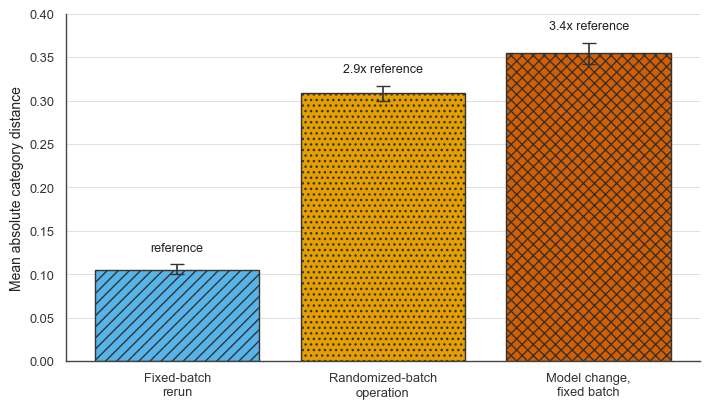

In [13]:
# Supplementary plot: fixed versus randomized batching (description-bootstrap intervals).
variation = pd.read_csv(TABLES / "variation_decomposition.csv")
fig, ax = plt.subplots(figsize=(7.2, 4.2))
x = np.arange(len(variation))
errors = np.vstack(
    [
        variation["mean_ordinal_distance"] - variation["ci_low"],
        variation["ci_high"] - variation["mean_ordinal_distance"],
    ]
)
bars = ax.bar(
    x,
    variation["mean_ordinal_distance"],
    color=OPERATION_COLORS,
    edgecolor="#333333",
    linewidth=1.0,
)
for bar, hatch in zip(bars, ["///", "...", "xxx"]):
    bar.set_hatch(hatch)
ax.errorbar(
    x,
    variation["mean_ordinal_distance"],
    yerr=errors,
    fmt="none",
    ecolor="#333333",
    capsize=5,
    linewidth=1.2,
)
for position, row in variation.iterrows():
    label = "reference" if position == 0 else f"{row['relative_to_fixed_rerun']:.1f}x reference"
    ax.text(position, row["ci_high"] + 0.012, label, ha="center", va="bottom", fontsize=9)
ax.set_xticks(x, ["Fixed-batch\nrerun", "Randomized-batch\noperation", "Model change,\nfixed batch"])
ax.set_ylabel("Mean absolute category distance")
ax.set_ylim(0, 0.40)
ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "variation_decomposition_color")


### Supplementary full-description disagreement

Each unique description receives equal weight; Figure 1 instead uses validation claim weights.


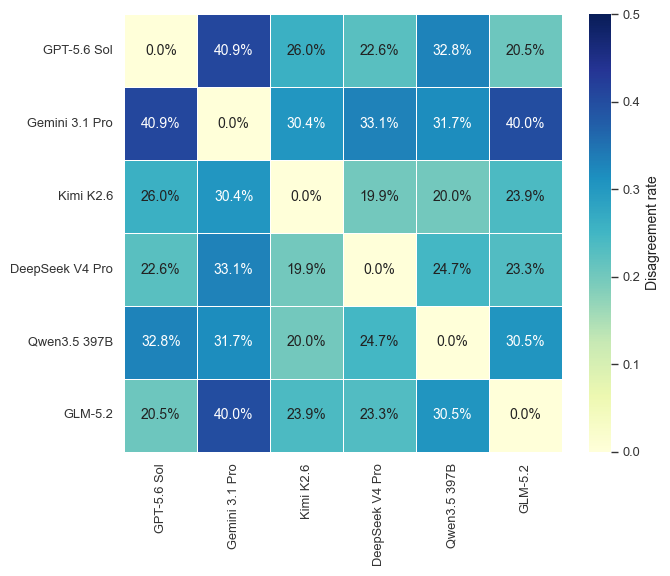

In [14]:
# Supplementary plot: full-description pairwise disagreement.
between = pd.read_csv(TABLES / "pairwise_behavior.csv")
heat = pd.DataFrame(np.zeros((len(MODELS), len(MODELS))), index=MODELS, columns=MODELS)
for row in between.itertuples():
    heat.loc[row.model_a, row.model_b] = row.disagreement_rate
    heat.loc[row.model_b, row.model_a] = row.disagreement_rate
fig, ax = plt.subplots(figsize=(7.0, 5.8))
sns.heatmap(
    heat,
    annot=True,
    fmt=".1%",
    cmap="YlGnBu",
    vmin=0,
    vmax=0.5,
    square=True,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Disagreement rate"},
    ax=ax,
)
for text, value in zip(ax.texts, heat.to_numpy().ravel()):
    text.set_color("white" if value >= 0.30 else "#222222")
ax.set_xlabel("")
ax.set_ylabel("")
fig.tight_layout()
save(fig, "pairwise_disagreement_color")


### Figure 2(a): category shares

All 4,690 descriptions receive equal weight.


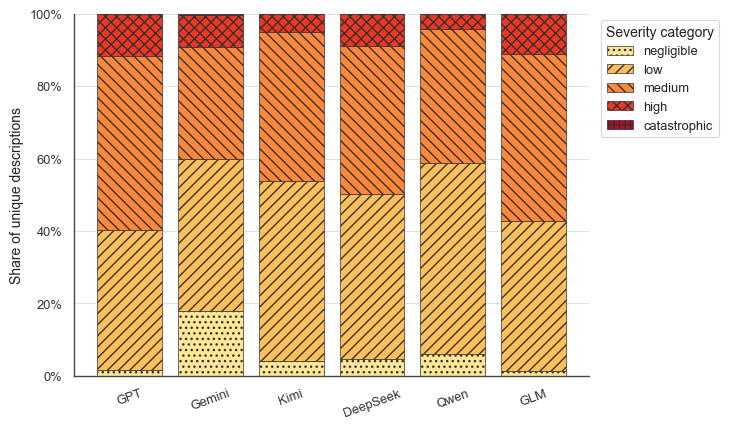

In [15]:
# Figure 2(a): model-specific category use.
mapping = pd.read_csv(TABLES / "severity_mapping.csv")
use = (
    mapping.pivot(index="model", columns="modal_label", values="share")
    .fillna(0)
    .reindex(index=MODELS, columns=LABELS)
)
fig, ax = plt.subplots(figsize=(7.4, 4.4))
bottom = np.zeros(len(MODELS))
hatches = ["...", "///", "\\\\\\", "xxx", "+++"]
for label, color, hatch in zip(LABELS, SEVERITY_COLORS, hatches):
    values = use[label].to_numpy()
    ax.bar(
        np.arange(len(MODELS)),
        values,
        bottom=bottom,
        label=label,
        color=color,
        edgecolor="#333333",
        linewidth=0.5,
        hatch=hatch,
    )
    bottom += values
ax.set_xticks(np.arange(len(MODELS)), [SHORT[m] for m in MODELS], rotation=20)
ax.set_ylabel("Share of unique descriptions")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend(title="Severity category", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "severity_mapping_color")


### Figure 2(b): empirical loss profiles

Loss summaries use training claims only; the vertical axis is logarithmic.


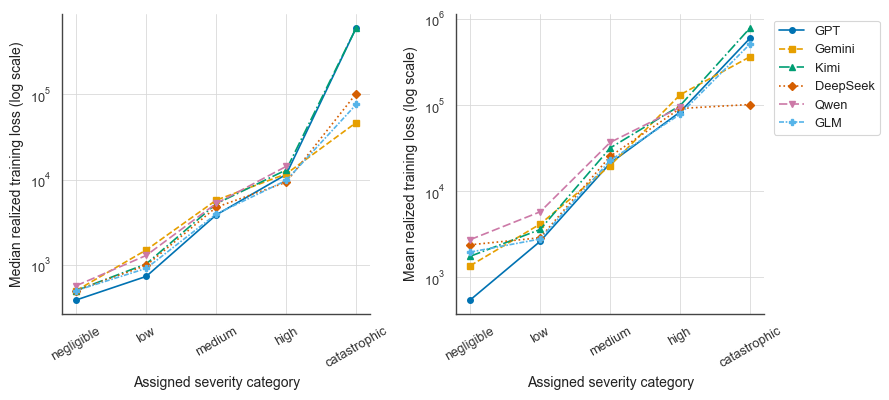

Wrote manuscript PDF figures to paper_naaj/figures


In [16]:
# Figure 2(b): empirical training loss within labels.
fig, axes = plt.subplots(1, 2, figsize=(9.0, 4.1), sharex=True)
line_styles = ["-", "--", "-.", ":", (0, (5, 2)), (0, (3, 1, 1, 1))]
markers = ["o", "s", "^", "D", "v", "P"]
for model, line_style, marker in zip(MODELS, line_styles, markers):
    sub = mapping.loc[mapping["model"].eq(model)].sort_values("modal_value")
    axes[0].plot(
        sub["modal_value"],
        sub["median_loss"],
        color=MODEL_COLORS[model],
        linestyle=line_style,
        marker=marker,
        markersize=4,
        label=SHORT[model],
    )
    axes[1].plot(
        sub["modal_value"],
        sub["mean_loss"],
        color=MODEL_COLORS[model],
        linestyle=line_style,
        marker=marker,
        markersize=4,
        label=SHORT[model],
    )
for ax, statistic in zip(axes, ["Median", "Mean"]):
    ax.set_yscale("log")
    ax.set_xticks(range(1, 6), LABELS, rotation=30)
    ax.set_xlabel("Assigned severity category")
    ax.set_ylabel(f"{statistic} realized training loss (log scale)")
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout()
save(fig, "empirical_loss_boundaries_color")

print(f"Wrote manuscript PDF figures to {OUT.relative_to(ROOT)}")


## Core result checks

**Reports:** Table 3, Figure 2, stable disagreements, and the original supplementary diagnostics. These checks cover selected core values; Notebooks 3–5 generate and check the extended results and current validation-weighted comparisons.


In [17]:
# Check the core study values and supplementary full-description diagnostics.
claim_rows = []

def audit_value(claim, manuscript_location, computed, reported, fmt):
    displayed = format(float(computed), fmt)
    claim_rows.append({
        "claim": claim,
        "manuscript_location": manuscript_location,
        "computed": computed,
        "displayed": displayed,
        "reported": str(reported),
        "match": displayed == str(reported),
    })

def audit_exact(claim, manuscript_location, computed, reported):
    claim_rows.append({
        "claim": claim,
        "manuscript_location": manuscript_location,
        "computed": computed,
        "displayed": str(computed),
        "reported": str(reported),
        "match": computed == reported,
    })


### Sample, inference, and performance checks

**Reports:** §§3.1–3.2, §4.1, and Table 3.


In [18]:
data_by_split = claims.groupby("split").agg(
    claims=("Loss", "size"),
    descriptions=("description_id", "nunique"),
    median_loss=("Loss", "median"),
    mean_loss=("Loss", "mean"),
)
for split, expected_values in {
    "train": (4_991, 3_733, "2,243", "19,297"),
    "validation": (1_039, 996, "3,240", "21,488"),
}.items():
    audit_exact(f"{split} claims", '§3.1', int(data_by_split.loc[split, "claims"]), expected_values[0])
    audit_exact(f"{split} descriptions", '§3.1', int(data_by_split.loc[split, "descriptions"]), expected_values[1])
    audit_value(f"{split} median loss", '§3.1', data_by_split.loc[split, "median_loss"], expected_values[2], ",.0f")
    audit_value(f"{split} mean loss", '§3.1', data_by_split.loc[split, "mean_loss"], expected_values[3], ",.0f")
audit_exact("combined claims", '§3.1', len(claims), 6_030)
audit_exact("combined descriptions", '§3.1', len(descriptions), 4_690)
audit_value("combined median loss", '§3.1', claims["Loss"].median(), "2,392", ",.0f")
audit_value("combined mean loss", '§3.1', claims["Loss"].mean(), "19,675", ",.0f")
audit_value("baseline validation R2", '§3.1', baseline.query("split == 'validation'")["r2"].iloc[0], "0.3398", ".4f")
audit_value("baseline validation MAE", '§3.1', baseline_mae, "1.0694", ".4f")

randomized_responses = labels[["model", "run", "batch_id"]].drop_duplicates().shape[0]
fixed_responses = fixed_labels[["model", "run", "batch_id"]].drop_duplicates().shape[0]
audit_exact("randomized classifications", '§3.2', len(labels), 140_700)
audit_exact("fixed classifications", '§3.2', len(fixed_labels), 30_000)
audit_exact("all classifications", '§3.2', len(labels) + len(fixed_labels), 170_700)
audit_exact("randomized logical responses", '§3.2', randomized_responses, 7_050)
audit_exact("fixed logical responses", '§3.2', fixed_responses, 1_500)
audit_exact("all logical responses", '§3.2', randomized_responses + fixed_responses, 8_550)
audit_exact("fixed descriptions", '§3.2', fixed_manifest["description_id"].nunique(), 1_000)
audit_exact("fixed batches", '§3.2', fixed_manifest["batch_id"].nunique(), 50)
audit_exact("augmented regressions", '§3.1', len(validation_performance), 30)

reported_performance = {
    "GPT-5.6 Sol": ("0.9906", "0.0133", "0.4283", "7.37"),
    "Gemini 3.1 Pro": ("0.9794", "0.0039", "0.4356", "8.41"),
    "Kimi K2.6": ("1.0037", "0.0091", "0.4100", "6.14"),
    "DeepSeek V4 Pro": ("1.0050", "0.0051", "0.4137", "6.02"),
    "Qwen3.5 397B": ("1.0143", "0.0026", "0.4046", "5.15"),
    "GLM-5.2": ("1.0006", "0.0095", "0.4151", "6.44"),
}
perf_index = performance_summary.set_index("model")
boot_index = mae_improvement_bootstrap.set_index("model")
for model, reported in reported_performance.items():
    audit_value(f"{model} mean MAE", '§4.1; Table 3; SUPPLEMENT.md', perf_index.loc[model, "mean_mae"], reported[0], ".4f")
    audit_value(f"{model} MAE SD", '§4.1; Table 3; SUPPLEMENT.md', perf_index.loc[model, "sd_mae"], reported[1], ".4f")
    audit_value(f"{model} mean R2", '§4.1; Table 3; SUPPLEMENT.md', perf_index.loc[model, "mean_r2"], reported[2], ".4f")
    audit_value(f"{model} MAE gain percent", '§4.1; Table 3; SUPPLEMENT.md', boot_index.loc[model, "mean_improvement_pct_baseline"], reported[3], ".2f")
audit_exact("all model mean MAEs improve on baseline", '§4.1; Table 3; SUPPLEMENT.md', bool((perf_index["mean_mae"].astype(float) < baseline_mae).all()), True)
audit_exact("all MAE bootstrap intervals exclude zero", '§4.1; Table 3; SUPPLEMENT.md', bool((mae_improvement_bootstrap["ci_low"] > 0).all()), True)

reported_bootstrap = {
    "GPT-5.6 Sol": ("0.0788", "0.0583", "0.0987"),
    "Gemini 3.1 Pro": ("0.0900", "0.0681", "0.1130"),
    "Kimi K2.6": ("0.0657", "0.0492", "0.0832"),
    "DeepSeek V4 Pro": ("0.0644", "0.0463", "0.0823"),
    "Qwen3.5 397B": ("0.0551", "0.0398", "0.0703"),
    "GLM-5.2": ("0.0688", "0.0509", "0.0868"),
}
for model, reported in reported_bootstrap.items():
    audit_value(f"{model} MAE improvement", '§4.1; Table 3; SUPPLEMENT.md', boot_index.loc[model, "mean_mae_improvement"], reported[0], ".4f")
    audit_value(f"{model} MAE improvement CI low", '§4.1; Table 3; SUPPLEMENT.md', boot_index.loc[model, "ci_low"], reported[1], ".4f")
    audit_value(f"{model} MAE improvement CI high", '§4.1; Table 3; SUPPLEMENT.md', boot_index.loc[model, "ci_high"], reported[2], ".4f")


### Supplementary variation and agreement checks

These checks retain the original full-description population; Notebook 5 verifies the validation-weighted results.


In [19]:
reported_operational_by_model = {
    "GPT-5.6 Sol": ("0.1342", "0.2796"),
    "Gemini 3.1 Pro": ("0.0818", "0.2574"),
    "Kimi K2.6": ("0.1182", "0.2984"),
    "DeepSeek V4 Pro": ("0.1134", "0.3416"),
    "Qwen3.5 397B": ("0.0566", "0.3504"),
    "GLM-5.2": ("0.1284", "0.3218"),
}
variation_model_index = variation_by_model.set_index("model")
for model, reported in reported_operational_by_model.items():
    audit_value(f"{model} fixed-batch distance", 'SUPPLEMENT.md: variation diagnostics', variation_model_index.loc[model, "fixed_batch_rerun_distance"], reported[0], ".4f")
    audit_value(f"{model} randomized-batch distance", 'SUPPLEMENT.md: variation diagnostics', variation_model_index.loc[model, "randomized_batch_operational_distance"], reported[1], ".4f")

variation_index = variation_summary.set_index("source")
reported_variation = {
    "Fixed-batch rerun": ("0.105", "0.100", "0.112", "1.0"),
    "Randomized-batch operation": ("0.308", "0.300", "0.317", "2.9"),
    "Model change, fixed batch": ("0.354", "0.342", "0.367", "3.4"),
}
for source, reported in reported_variation.items():
    audit_value(f"{source} distance", 'SUPPLEMENT.md: variation diagnostics', variation_index.loc[source, "mean_ordinal_distance"], reported[0], ".3f")
    audit_value(f"{source} CI low", 'SUPPLEMENT.md: variation diagnostics', variation_index.loc[source, "ci_low"], reported[1], ".3f")
    audit_value(f"{source} CI high", 'SUPPLEMENT.md: variation diagnostics', variation_index.loc[source, "ci_high"], reported[2], ".3f")
    audit_value(f"{source} relative distance", 'SUPPLEMENT.md: variation diagnostics', variation_index.loc[source, "relative_to_fixed_rerun"], reported[3], ".1f")
audit_value("fixed-vs-randomized modal disagreement minimum", 'SUPPLEMENT.md: variation diagnostics', variation_by_model["fixed_vs_randomized_modal_disagreement"].min() * 100, "16.9", ".1f")
audit_value("fixed-vs-randomized modal disagreement maximum", 'SUPPLEMENT.md: variation diagnostics', variation_by_model["fixed_vs_randomized_modal_disagreement"].max() * 100, "21.9", ".1f")
audit_exact("fixed-vs-randomized shifts of two-plus are rare", 'SUPPLEMENT.md: variation diagnostics', bool((variation_by_model["fixed_vs_randomized_modal_two_plus"] < 0.01).all()), True)

for threshold, expected_pairs, expected_min, expected_median, expected_max in [
    (0.5, 3, "19.9", "23.3", "23.9"),
    (1.0, 6, "19.9", "21.9", "24.7"),
    (2.0, 11, "19.9", "23.9", "40.9"),
]:
    row = equivalence_threshold_sensitivity.query("threshold_pct_baseline_mae == @threshold").iloc[0]
    audit_exact(f"{threshold}% tolerance pair count", 'SUPPLEMENT.md: full-description agreement', int(row["equivalent_pairs"]), expected_pairs)
    audit_value(f"{threshold}% tolerance disagreement minimum", 'SUPPLEMENT.md: full-description agreement', row["min_disagreement_rate"] * 100, expected_min, ".1f")
    audit_value(f"{threshold}% tolerance disagreement median", 'SUPPLEMENT.md: full-description agreement', row["median_disagreement_rate"] * 100, expected_median, ".1f")
    audit_value(f"{threshold}% tolerance disagreement maximum", 'SUPPLEMENT.md: full-description agreement', row["max_disagreement_rate"] * 100, expected_max, ".1f")

reported_pairs = {
    ("Kimi K2.6", "DeepSeek V4 Pro"): ("0.12", "19.9"),
    ("Kimi K2.6", "GLM-5.2"): ("0.30", "23.9"),
    ("DeepSeek V4 Pro", "Qwen3.5 397B"): ("0.87", "24.7"),
    ("GPT-5.6 Sol", "GLM-5.2"): ("0.93", "20.5"),
}
for (model_a, model_b), reported in reported_pairs.items():
    row = equivalence.query("model_a == @model_a and model_b == @model_b").iloc[0]
    audit_value(f"{model_a} vs {model_b} MAE difference percent", 'SUPPLEMENT.md: full-description agreement', row["mae_difference_pct_baseline"], reported[0], ".2f")
    audit_value(f"{model_a} vs {model_b} disagreement percent", 'SUPPLEMENT.md: full-description agreement', row["disagreement_rate"] * 100, reported[1], ".1f")
audit_value("pairwise disagreement minimum", 'SUPPLEMENT.md: full-description agreement', between["disagreement_rate"].min() * 100, "19.9", ".1f")
audit_value("pairwise disagreement maximum", 'SUPPLEMENT.md: full-description agreement', between["disagreement_rate"].max() * 100, "40.9", ".1f")
audit_value("weighted kappa minimum", 'SUPPLEMENT.md: full-description agreement', between["weighted_kappa"].min(), "0.67", ".2f")
audit_value("weighted kappa maximum", 'SUPPLEMENT.md: full-description agreement', between["weighted_kappa"].max(), "0.79", ".2f")


### Category profiles and stable-disagreement checks

**Reports:** §4.3 and Figure 2; incident cases remain descriptive.


In [20]:
category_index = category_use.set_index(["model", "modal_label"])
for model, label, reported in [
    ("Gemini 3.1 Pro", "negligible", "17.8"),
    ("GPT-5.6 Sol", "negligible", "1.7"),
    ("GLM-5.2", "negligible", "1.4"),
    ("Qwen3.5 397B", "low", "52.8"),
    ("GPT-5.6 Sol", "low", "38.7"),
    ("Qwen3.5 397B", "high", "4.1"),
    ("GPT-5.6 Sol", "high", "11.6"),
]:
    audit_value(f"{model} {label} share percent", '§4.3; Figure 2; SUPPLEMENT.md', category_index.loc[(model, label), "share"] * 100, reported, ".1f")
audit_exact("Qwen catastrophic descriptions", '§4.3; Figure 2; SUPPLEMENT.md', int(category_index.loc[("Qwen3.5 397B", "catastrophic"), "descriptions"]), 0)
for label, low_reported, high_reported in [
    ("low", "733", "1,494"),
    ("medium", "3,850", "5,726"),
    ("high", "9,296", "14,249"),
]:
    values = loss_by_severity.query("modal_label == @label")["median_loss"].dropna()
    audit_value(f"{label} median-loss minimum", '§4.3; Figure 2; SUPPLEMENT.md', values.min(), low_reported, ",.0f")
    audit_value(f"{label} median-loss maximum", '§4.3; Figure 2; SUPPLEMENT.md', values.max(), high_reported, ",.0f")

audit_exact("strict stable-disagreement descriptions", '§4.3; Figure 2; SUPPLEMENT.md', len(stable_set), 11)
audit_value("strict stable-disagreement share percent", '§4.3; Figure 2; SUPPLEMENT.md', len(stable_set) / len(descriptions) * 100, "0.23", ".2f")
audit_value("jointly stable share minimum percent", '§4.3; Figure 2; SUPPLEMENT.md', stable_pairwise["jointly_stable_share"].min() * 100, "47.3", ".1f")
audit_value("jointly stable share maximum percent", '§4.3; Figure 2; SUPPLEMENT.md', stable_pairwise["jointly_stable_share"].max() * 100, "57.9", ".1f")
audit_value("stable-pair disagreement minimum percent", '§4.3; Figure 2; SUPPLEMENT.md', stable_pairwise["disagreement_among_jointly_stable"].min() * 100, "7.1", ".1f")
audit_value("stable-pair disagreement maximum percent", '§4.3; Figure 2; SUPPLEMENT.md', stable_pairwise["disagreement_among_jointly_stable"].max() * 100, "35.9", ".1f")

joint_count = disagreement_count = adjacent_count = two_plus_count = 0
for model_a, model_b in combinations(MODEL_ORDER, 2):
    a = modal.query("model == @model_a")[["description_id", "modal_value", "modal_count"]].rename(columns={"modal_value": "a", "modal_count": "ca"})
    b = modal.query("model == @model_b")[["description_id", "modal_value", "modal_count"]].rename(columns={"modal_value": "b", "modal_count": "cb"})
    joined = a.merge(b, on="description_id", validate="one_to_one").query("ca >= 4 and cb >= 4")
    distance = (joined["a"] - joined["b"]).abs()
    joint_count += len(distance)
    disagreement_count += int((distance > 0).sum())
    adjacent_count += int((distance == 1).sum())
    two_plus_count += int((distance >= 2).sum())
audit_value("aggregate stable-pair disagreement percent", '§4.3; Figure 2; SUPPLEMENT.md', disagreement_count / joint_count * 100, "17.4", ".1f")
audit_value("adjacent share among stable disagreements percent", '§4.3; Figure 2; SUPPLEMENT.md', adjacent_count / disagreement_count * 100, "99.7", ".1f")
audit_value("two-plus share among stable disagreements percent", '§4.3; Figure 2; SUPPLEMENT.md', two_plus_count / disagreement_count * 100, "0.3", ".1f")

example_expectations = {
    "power outage at Riverside Pumping Station": (50_303.11, "medium (5/5)", "negligible (4/5)"),
    "surveillance system missing": (13_905.00, "low (4/5)", "high (4/5)"),
    "winter glove flushed, got caught in grinder pipe": (4_118.00, "medium (4/5)", "negligible (4/5)"),
    "power surge damaged projector": (956.99, "negligible (4/5)", "medium (4/5)"),
}
for description, (loss, mapping_a, mapping_b) in example_expectations.items():
    row = stable_set.query("Description == @description").iloc[0]
    audit_value(f"example loss: {description}", '§4.3; Figure 2; SUPPLEMENT.md', row["median_loss"], format(loss, ",.0f"), ",.0f")
    mappings = set(row[MODEL_ORDER].astype(str))
    audit_exact(f"example mapping A: {description}", '§4.3; Figure 2; SUPPLEMENT.md', mapping_a in mappings, True)
    audit_exact(f"example mapping B: {description}", '§4.3; Figure 2; SUPPLEMENT.md', mapping_b in mappings, True)


### Figure files and audit output

Require the four plots owned by this notebook and save the combined core result checks.


In [21]:
figure_stems = [
    "variation_decomposition_color",
    "pairwise_disagreement_color",
    "severity_mapping_color",
    "empirical_loss_boundaries_color",
]
for stem in figure_stems:
    audit_exact(f"study figure exists: {stem}", '§4.3; Figure 2; SUPPLEMENT.md', (OUT / f"{stem}.pdf").exists(), True)

claim_audit = pd.DataFrame(claim_rows)
claim_audit.to_csv(TABLES / "manuscript_claim_audit.csv", index=False)
failures = claim_audit.loc[~claim_audit["match"]]
display(claim_audit)
assert failures.empty, "Manuscript claim mismatches:\n" + failures.to_string(index=False)
print(f"Verified {len(claim_audit)} manuscript values and artifact checks; all match.")


,claim,manuscript_location,computed,displayed,reported,match
0,train claims,§3.1,4991,4991,4991,True
1,train descriptions,§3.1,3733,3733,3733,True
2,train median loss,§3.1,2243.28,"2,243","2,243",True
3,train mean loss,§3.1,19297.05426,"19,297","19,297",True
4,validation claims,§3.1,1039,1039,1039,True
...,...,...,...,...,...,...
152,example mapping B: power surge damaged projector,§4.3; Figure 2; SUPPLEMENT.md,True,True,True,True
153,study figure exists: variation_decomposition_c...,§4.3; Figure 2; SUPPLEMENT.md,True,True,True,True
154,study figure exists: pairwise_disagreement_color,§4.3; Figure 2; SUPPLEMENT.md,True,True,True,True
155,study figure exists: severity_mapping_color,§4.3; Figure 2; SUPPLEMENT.md,True,True,True,True


Verified 157 manuscript values and artifact checks; all match.
